# Iris Flower Classification Using Machine Learning

**Name:** Tusiime Emily Queen  
**Internship:** Oasis Infobyte (OIBSIP)  
**Track:** Data Science  
**Task:** 1 - Iris Flower Classification

## Project Objective

The objective of this project is to build and evaluate machine learning
classification models that predict the species of an Iris flower using
its physical measurements.

The three species are:
- Iris Setosa
- Iris Versicolor
- Iris Virginica

The four input features are:
- Sepal length
- Sepal width
- Petal length
- Petal width

## Project Workflow

1. Import the required libraries
2. Load the Iris dataset
3. Perform Exploratory Data Analysis (EDA)
4. Visualize feature distributions
5. Discuss feature selection
6. Split the dataset into training and testing sets
7. Train multiple classification models
8. Evaluate and compare model performance
9. Identify the best-performing model
10. Present conclusions

## Technologies Used

Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn,
and Jupyter Notebook.

In [10]:
import sys

print("Welcome to Oasis Infobyte Data Science Internship!")
print("Python version:", sys.version)
print("Python environment:", sys.executable)

Welcome to Oasis Infobyte Data Science Internship!
Python version: 3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]
Python environment: C:\Users\HP OMNI BOOK X\Documents\OIBSIP\venv\Scripts\python.exe


In [11]:
# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning dataset
from sklearn.datasets import load_iris

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [12]:
# Load the Iris dataset from scikit-learn
iris = load_iris()

# Convert the features into a pandas DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the flower species names
df["species"] = iris.target_names[iris.target]

# Display the first five records
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the structure,
quality, and statistical characteristics of the Iris dataset before
training machine learning models.

The analysis includes:
- Dataset shape and dimensions
- Data types
- Missing values
- Descriptive statistics
- Distribution of flower species

In [13]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset Shape: (150, 5)
Number of rows: 150
Number of columns: 5


In [14]:
# Examine the data types of each column
print("Dataset Data Types:")
print(df.dtypes)

# Display additional dataset information
df.info()

Dataset Data Types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                  str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [15]:
# Check for missing values in each column
print("Missing Values per Column:")
print(df.isnull().sum())

# Check the total number of missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values per Column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Total Missing Values: 0


In [16]:
# Generate descriptive statistics for numerical features
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [17]:
# Count observations for each Iris species
print("Species Distribution:")
print(df["species"].value_counts())

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### EDA Observations

1. The Iris dataset contains 150 observations and 5 columns.
2. Four columns represent numerical flower measurements.
3. The species column is the target variable for classification.
4. The dataset contains no missing values.
5. The dataset contains three flower species: Setosa,
   Versicolor, and Virginica.
6. Each species has 50 observations, indicating a balanced dataset.

These findings show that the dataset is suitable for
classification analysis without missing-value imputation.

## 3. Data Visualization

Data visualization helps us identify patterns, relationships,
distributions, and potential outliers in the Iris dataset.

In this section, we will use:
1. Pairplots to examine relationships between flower measurements.
2. Box plots to compare feature distributions across species.

These visualizations will help us understand which features
are most useful for Iris flower classification.

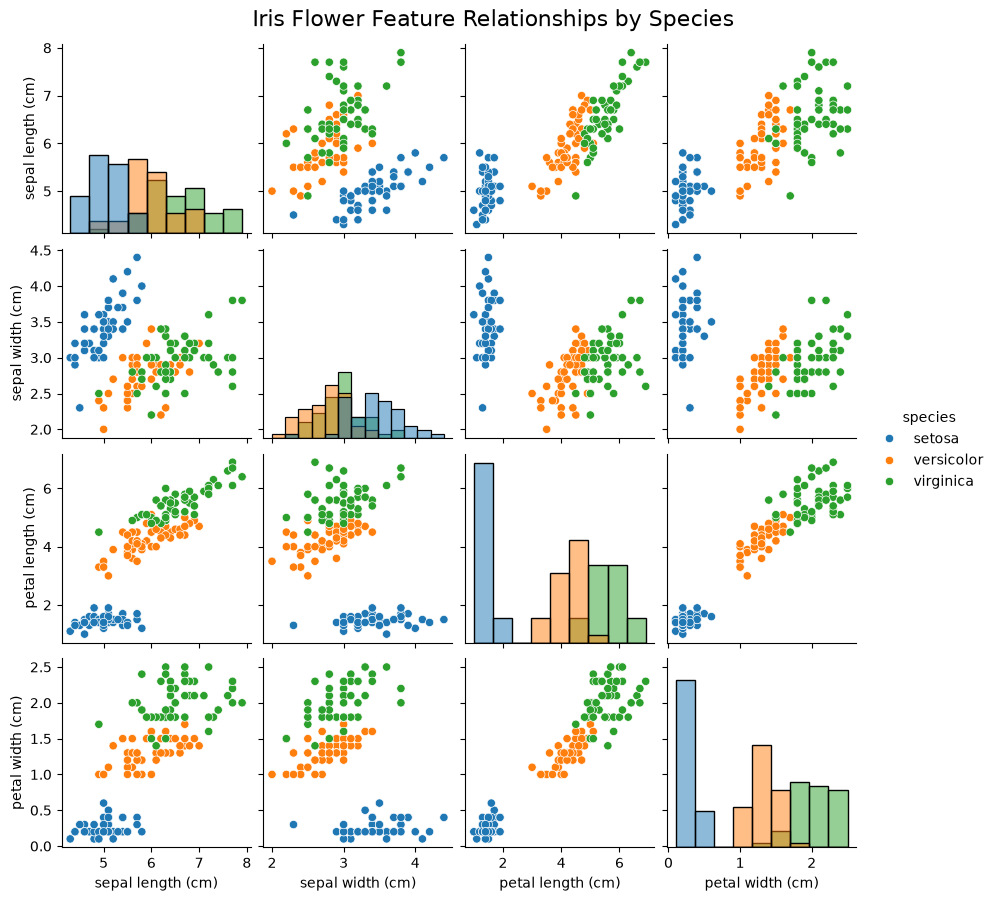

In [18]:
# Create a pairplot to compare flower measurements by species

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist",
    height=2.2
)

plt.suptitle(
    "Iris Flower Feature Relationships by Species",
    y=1.02,
    fontsize=16
)

plt.show()

### Pairplot Observations

1. Iris Setosa forms a clearly separated cluster, particularly
   when comparing petal length and petal width.

2. Iris Versicolor and Iris Virginica show some overlap,
   making their classification more challenging.

3. Petal length and petal width appear to provide stronger
   separation between species than sepal measurements.

4. Sepal length and sepal width show more overlapping
   distributions across the three species.

These findings suggest that petal measurements may be
particularly useful for predicting Iris flower species.

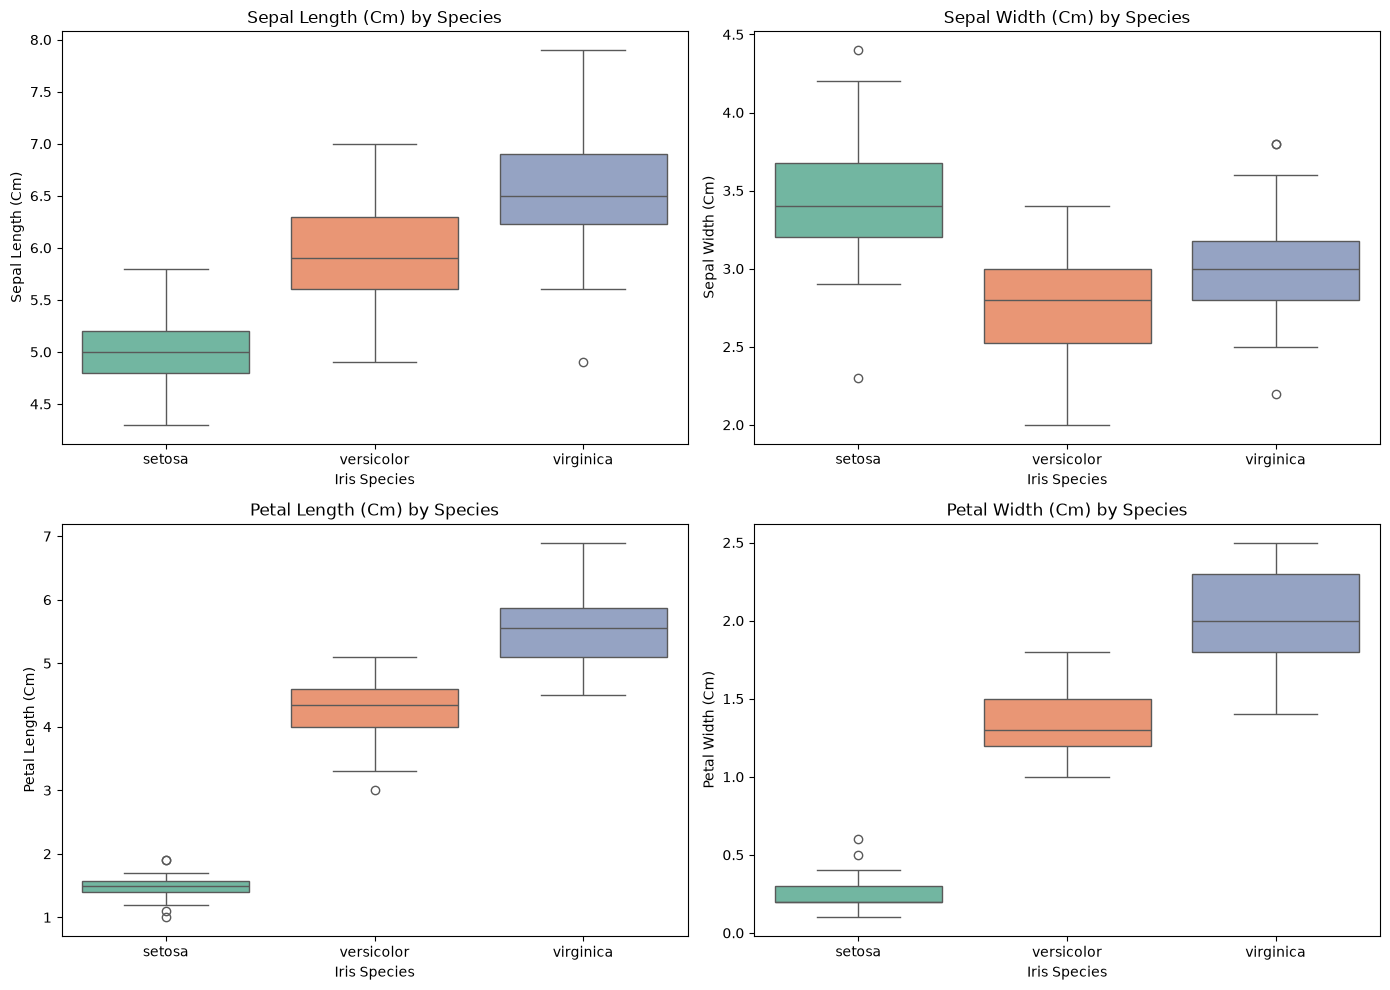

In [19]:
# Select the four numerical features
features = iris.feature_names

# Create a figure with four box plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loop through each feature and create its box plot
for i, feature in enumerate(features):

    row = i // 2
    col = i % 2

    sns.boxplot(
        data=df,
        x="species",
        y=feature,
        hue="species",
        palette="Set2",
        legend=False,
        ax=axes[row, col]
    )

    axes[row, col].set_title(
        f"{feature.title()} by Species"
    )

    axes[row, col].set_xlabel("Iris Species")
    axes[row, col].set_ylabel(feature.title())

# Adjust spacing
plt.tight_layout()

# Display the plots
plt.show()

### Box Plot Observations

1. Petal length and petal width show noticeable differences
   between the three Iris species.

2. Setosa generally has the smallest petal measurements.

3. Virginica generally has the largest petal measurements.

4. Versicolor typically falls between Setosa and Virginica
   in petal measurements.

5. Sepal measurements show greater overlap across species,
   suggesting that they may be less discriminative.

Overall, petal length and petal width appear to be the
strongest features for distinguishing Iris species.

## 4. Feature Selection

Feature selection involves identifying the input variables
that are most useful for predicting the target variable.

Based on the exploratory data analysis and visualizations:

- Petal length provides strong separation between Iris species.
- Petal width also shows clear differences between species.
- Sepal length provides some useful information.
- Sepal width shows greater overlap between species.

Although petal length and petal width appear most
discriminative, all four numerical features will initially
be retained for model training.

The species column is the target variable and must not
be included among the input features.

In [20]:
# Select the four input features
X = df.drop(columns=["species"])

# Select the target variable
y = df["species"]

# Display the dimensions
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

# Display feature names
print("\nSelected features:")
print(X.columns.tolist())

# Display target classes
print("\nTarget classes:")
print(y.unique())

Feature matrix shape: (150, 4)
Target vector shape: (150,)

Selected features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target classes:
<StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str


## 5. Train-Test Split

The dataset is divided into 80% training data and
20% testing data.

Training data is used to teach the machine learning models
to recognize patterns in flower measurements.

Testing data is reserved for evaluating how well the trained
models classify previously unseen observations.

A random state of 42 ensures reproducibility.

Stratified sampling is used to preserve the proportion
of each Iris species in both datasets.

In [21]:
# Import the train-test split function
from sklearn.model_selection import train_test_split

# Split features and labels into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes of the datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

# Verify class balance
print("\nTraining species distribution:")
print(y_train.value_counts())

print("\nTesting species distribution:")
print(y_test.value_counts())

Training features: (120, 4)
Testing features: (30, 4)
Training labels: (120,)
Testing labels: (30,)

Training species distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing species distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## 6. Machine Learning Model Training

In this section, three classification algorithms are trained
to predict Iris flower species.

The models used are:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Random Forest Classifier

The models are trained using 80% of the dataset.

The remaining 20% is reserved for evaluating model
performance on unseen data.

Logistic Regression and KNN will use feature scaling
through a StandardScaler pipeline.

Random Forest does not require feature scaling because
it uses decision trees.

In [22]:
# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Import preprocessing and pipeline utilities
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

print("Machine learning algorithms imported successfully!")

Machine learning algorithms imported successfully!


### 6.1 Logistic Regression

Logistic Regression is used as the first classification model.

It estimates the probability that a flower belongs to
each of the three Iris species.

StandardScaler is used to standardize the numerical
features before training.

The model is trained using the training dataset only.

In [23]:
# Create a pipeline for scaling and Logistic Regression
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Train the model
logistic_model.fit(X_train, y_train)

# Predict flower species using the test dataset
logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression model trained successfully!")

# Display the first five predictions
print("First five predictions:", logistic_predictions[:5])

Logistic Regression model trained successfully!
First five predictions: ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa']


### 6.2 K-Nearest Neighbors (KNN)

KNN is a supervised classification algorithm that predicts
the class of a new observation based on its nearest neighbors.

In this project, K = 5.

The algorithm examines the five nearest training observations
and predicts the most common species among them.

Feature scaling is important because KNN calculates distances
between observations.

In [24]:
# Create a KNN pipeline with feature scaling
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train the KNN classifier
knn_model.fit(X_train, y_train)

# Make predictions on the test dataset
knn_predictions = knn_model.predict(X_test)

print("KNN model trained successfully!")

# Display the first five predictions
print("First five predictions:", knn_predictions[:5])

KNN model trained successfully!
First five predictions: ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa']


### 6.3 Random Forest Classifier

Random Forest is an ensemble machine learning algorithm
that combines predictions from multiple decision trees.

Each tree learns patterns from the training dataset.

The final classification is determined by combining
the predictions of the individual trees.

Random Forest can capture nonlinear relationships
between flower measurements and species.

In this project, 100 decision trees are used.

In [25]:
# Initialize Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the Random Forest model
rf_model.fit(X_train, y_train)

# Predict the species in the test dataset
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

# Display the first five predictions
print("First five predictions:", rf_predictions[:5])

Random Forest model trained successfully!
First five predictions: ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa']


In [26]:
# Store trained models in a dictionary
models = {
    "Logistic Regression": logistic_model,
    "K-Nearest Neighbors": knn_model,
    "Random Forest": rf_model
}

# Confirm model training
print("Successfully trained models:")

for model_name in models:
    print("-", model_name)

print("\nTotal models trained:", len(models))

Successfully trained models:
- Logistic Regression
- K-Nearest Neighbors
- Random Forest

Total models trained: 3


## 7. Model Evaluation and Comparison

After training the three machine learning classifiers,
their performance is evaluated using the reserved test dataset.

The evaluation metrics include:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. Confusion Matrix

The purpose is to compare how well each model predicts
Iris flower species and identify the best-performing classifier.

All three models are evaluated using the same test dataset
to ensure a fair comparison.

In [27]:
# Import model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [28]:
# Dictionary to store evaluation results
evaluation_results = []

# Evaluate each trained model
for model_name, model in models.items():

    # Make predictions using the test dataset
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    # Store the results
    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    # Display individual model results
    print(f"\n{'=' * 50}")
    print(f"Model: {model_name}")
    print(f"{'=' * 50}")

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


Model: Logistic Regression
Accuracy:  0.9333
Precision: 0.9333
Recall:    0.9333
F1-Score:  0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Model: K-Nearest Neighbors
Accuracy:  0.9333
Precision: 0.9444
Recall:    0.9333
F1-Score:  0.9327

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93  

### 7.1 Model Performance Comparison

The following table summarizes the performance of
the three classifiers using the same test dataset.

Models are compared using accuracy, precision,
recall, and F1-score.

In [29]:
# Convert evaluation results into a DataFrame
results_df = pd.DataFrame(evaluation_results)

# Sort models by F1-score, then accuracy
results_df = results_df.sort_values(
    by=["F1-Score", "Accuracy"],
    ascending=False
).reset_index(drop=True)

# Display results as percentages
display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,93.33%,93.33%,93.33%,93.33%
1,K-Nearest Neighbors,93.33%,94.44%,93.33%,93.27%
2,Random Forest,90.00%,90.24%,90.00%,89.97%


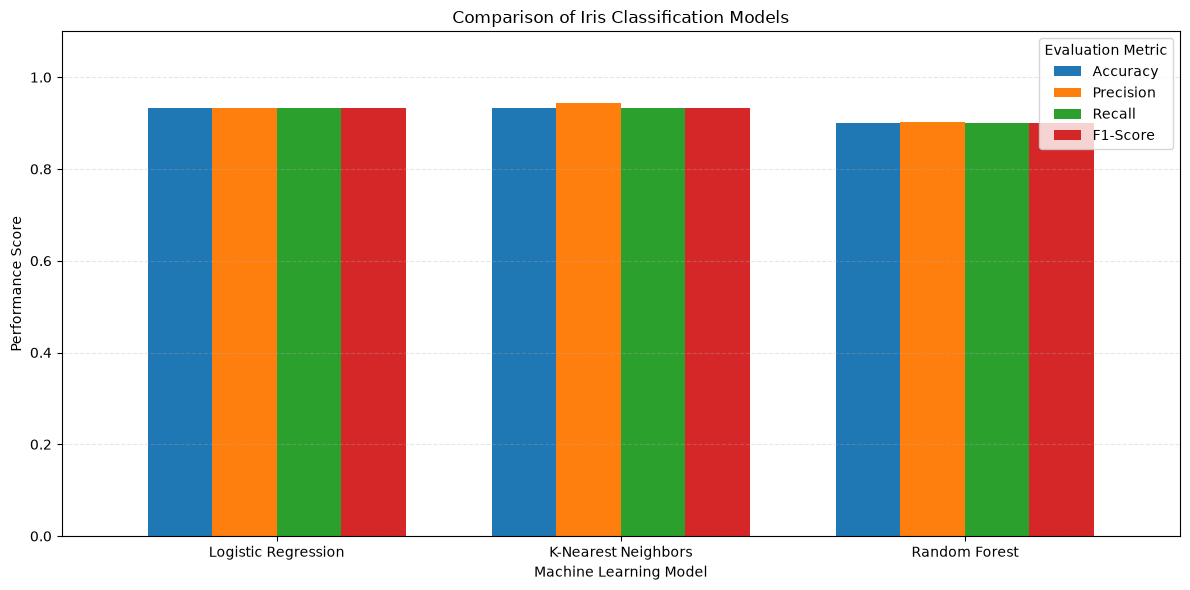

In [30]:
# Plot the performance metrics for all three models
plot_df = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("Comparison of Iris Classification Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Performance Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

### 7.2 Confusion Matrix Analysis

A confusion matrix evaluates classification performance
by comparing actual species labels with predicted labels.

The diagonal cells represent correct classifications.

Off-diagonal cells represent incorrect classifications.

A good classification model should have most predictions
concentrated along the main diagonal.

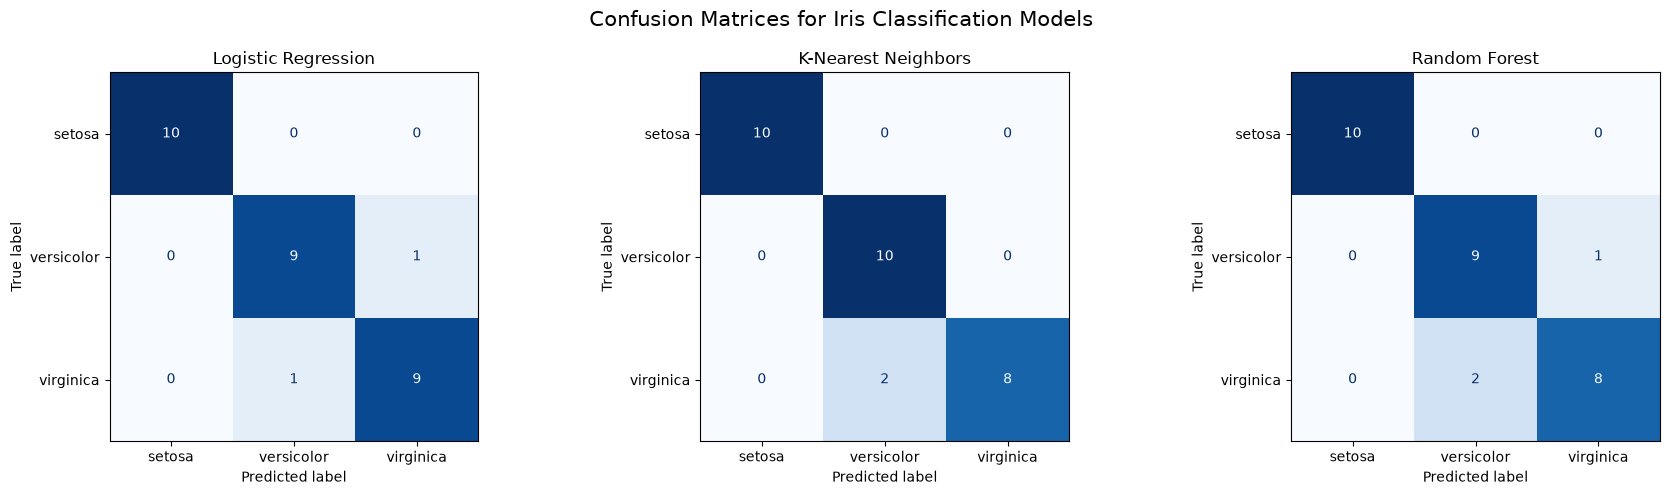

In [32]:
# Generate a confusion matrix for each classifier

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, model) in zip(axes, models.items()):

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=iris.target_names
    )

    # Display confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=iris.target_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(model_name)

plt.suptitle(
    "Confusion Matrices for Iris Classification Models",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 8. Best-Performing Model

The best-performing classification model is selected
based on its evaluation metrics.

Macro F1-score is used as the primary comparison metric
because it considers both precision and recall across
all three flower species.

Accuracy is used as a secondary metric.

The final model selection is based on test-set performance,
although additional cross-validation would provide a more
reliable estimate of generalization.

In [33]:
# Identify the best model from the comparison results
best_model_name = results_df.iloc[0]["Model"]

best_accuracy = results_df.iloc[0]["Accuracy"]
best_precision = results_df.iloc[0]["Precision"]
best_recall = results_df.iloc[0]["Recall"]
best_f1 = results_df.iloc[0]["F1-Score"]

# Retrieve the trained model
best_model = models[best_model_name]

print("BEST-PERFORMING MODEL")
print("=" * 40)

print("Model:", best_model_name)
print(f"Accuracy: {best_accuracy:.2%}")
print(f"Precision: {best_precision:.2%}")
print(f"Recall: {best_recall:.2%}")
print(f"F1-Score: {best_f1:.2%}")

print("\nThe model was selected based on its")
print("macro F1-score, with accuracy as a tie-breaker.")

BEST-PERFORMING MODEL
Model: Logistic Regression
Accuracy: 93.33%
Precision: 93.33%
Recall: 93.33%
F1-Score: 93.33%

The model was selected based on its
macro F1-score, with accuracy as a tie-breaker.


In [34]:
# Check for ties in the top two evaluation metrics
tied_models = results_df[
    np.isclose(results_df["F1-Score"], best_f1)
    & np.isclose(results_df["Accuracy"], best_accuracy)
]

if len(tied_models) > 1:
    print("Multiple models achieved the same top scores:")
    print(tied_models["Model"].to_string(index=False))
else:
    print("Unique top-performing model:", best_model_name)

Unique top-performing model: Logistic Regression


## 9. Conclusion

This project developed and evaluated three machine learning
classification algorithms for predicting Iris flower species:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Random Forest Classifier

### Key Findings

- The Iris dataset contained 150 observations across three species.
- The dataset had no missing values.
- Each species had 50 observations, indicating balanced classes.
- Exploratory Data Analysis showed that petal length and petal
  width provide strong separation between flower species.
- Three classification models were trained using an 80/20
  train-test split.
- Model performance was evaluated using accuracy, precision,
  recall, F1-score, and confusion matrices.

### Best-Performing Model

The best-performing model was identified using macro F1-score,
with accuracy used as a secondary comparison metric.

The final model selection and its numerical performance
are reported in the evaluation section above.

### Limitations

The dataset is relatively small, containing only 150 observations.
Model performance was evaluated using a single train-test split,
so the results may vary with different data partitions.

### Future Improvements

- Apply stratified cross-validation.
- Perform hyperparameter tuning.
- Compare performance using different feature subsets.
- Develop a simple application for predicting Iris species.

### Final Remarks

This project demonstrates the complete supervised machine
learning workflow, including data preparation, exploratory
analysis, visualization, model training, evaluation, and
comparison.